# Name That LLM — recovering prompt groups + grouped baseline

`train.csv` has only `text` and `model`, but the passages were written in response to ~150 prompts (≈18 passages per prompt, one per model).
The test set uses **unseen prompts**, so validation must keep a prompt's passages together. This notebook:

1. Recovers the hidden prompt groups by clustering passages on topic.
2. Uses the labels to check cluster quality (a clean cluster has ~18 passages and **no model twice**).
3. Shows why it matters: random-split CV vs GroupKFold on the recovered groups.
4. Saves `train_with_groups.csv` for later notebooks (GroupKFold, prompt-centering, Hungarian assignment).

Runs on Kaggle with internet off, or locally with `train.csv` next to the notebook.

In [16]:
import glob, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score, balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import normalize

SEED = 42
E5_PATH = None   # optional: path to an attached multilingual-e5-large-instruct folder
OUT = "/kaggle/working" if os.path.exists("/kaggle/working") else "."

## 1. Load data
Auto-detects the training file. **On Kaggle:** right panel → *Add Input* → *Competitions* → **Name That LLM**.
**Locally:** put `train.csv` (or the downloaded `name-that-llm.zip`) next to this notebook or in `data/`.
If detection still fails, set `TRAIN_PATH` by hand.

In [17]:
TRAIN_PATH = "train.csv"   # change to wherever you saved it, e.g. r"C:\Users\you\Downloads\train.csv"

df = pd.read_csv(TRAIN_PATH).dropna(subset=["text", "model"]).reset_index(drop=True)
print(df.shape, list(df.columns))

N_MODELS = df["model"].nunique()
K_GUESS = int(round(len(df) / N_MODELS))
df["n_words"] = df["text"].str.split().str.len()
print(f"{N_MODELS} models | expected prompts ≈ {len(df)}/{N_MODELS} = {K_GUESS}")
df["model"].value_counts().to_frame("passages").T

(2699, 4) ['id', 'prompt_id', 'text', 'model']
18 models | expected prompts ≈ 2699/18 = 150


model,qwen3.8-max,claude-sonnet-5,gemini-3.6-flash,gpt-5.6-terra,glm-5.3-flash,gemini-3.1-pro-preview,gemini-3.8-flash,claude-opus-4-6,gpt-5.6-luna,claude-opus-4-8,gemini-3.7-flash,claude-opus-5,kimi-k3,gpt-5.5,glm-5.3,gpt-6-astra,gpt-5.6-sol,claude-fable-5
passages,150,150,150,150,150,150,150,150,150,150,150,150,150,150,150,150,150,149


## 2. Topic representation
We want to group by **what the passage is about**, not who wrote it, so we keep only content words
(stopwords and very common words removed) and compress with LSA. If you attach e5, set `E5_PATH` to compare.

In [18]:
def embed_tfidf(texts, n_components=200):
    vec = TfidfVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
                          sublinear_tf=True, min_df=2, max_df=0.05)
    X = vec.fit_transform(texts)
    k = min(n_components, X.shape[1] - 1, X.shape[0] - 1)
    return normalize(TruncatedSVD(k, random_state=SEED).fit_transform(X))

def embed_e5(texts, path):
    from sentence_transformers import SentenceTransformer
    m = SentenceTransformer(path)
    task = "Instruct: Identify the topic or question this passage responds to\nQuery: "
    return m.encode([task + t for t in texts], batch_size=32, normalize_embeddings=True)

Z = embed_e5(df["text"].tolist(), E5_PATH) if E5_PATH else embed_tfidf(df["text"])
METHOD = "e5" if E5_PATH else "TF-IDF + LSA"
Z.shape

(2699, 200)

## 3. Cluster and score cluster quality across k

In [19]:
def cluster(Z, k):
    return AgglomerativeClustering(n_clusters=k, metric="cosine", linkage="average").fit_predict(Z)

def quality(groups):
    d = df.assign(group=groups)
    sizes = d.groupby("group").size()
    return {
        "k": int(groups.max() + 1),
        "pct_clusters_with_repeat": 100 * d.groupby("group")["model"].apply(lambda s: s.duplicated().any()).mean(),
        "pct_passages_duplicated": 100 * d.duplicated(["group", "model"]).mean(),
        "pct_clusters_size_ok": 100 * sizes.between(N_MODELS - 3, N_MODELS + 3).mean(),
        "median_size": sizes.median(), "max_size": sizes.max(), "singletons": int((sizes == 1).sum()),
    }

ks = sorted(set(np.linspace(K_GUESS * 0.6, K_GUESS * 1.5, 13).astype(int).tolist() + [K_GUESS]))
labels = {k: cluster(Z, k) for k in ks}
sweep = pd.DataFrame([quality(labels[k]) for k in ks])
sweep.round(1)

,k,pct_clusters_with_repeat,pct_passages_duplicated,pct_clusters_size_ok,median_size,max_size,singletons
0,90,43.3,40.0,56.7,18.0,90,0
1,101,34.7,32.6,65.3,18.0,90,0
2,112,26.8,25.3,73.2,18.0,55,0
3,123,17.9,18.0,82.1,18.0,55,0
4,135,11.1,10.0,89.6,18.0,55,0
5,146,4.8,3.3,95.9,18.0,36,1
6,150,2.7,2.0,95.3,18.0,36,2
7,157,2.5,1.2,92.4,18.0,36,5
8,168,2.4,1.2,85.1,18.0,36,13
9,180,1.7,1.1,77.8,18.0,36,22


In [20]:
K = K_GUESS            # change if the sweep suggests a better k
df["group"] = labels[K]
q = quality(labels[K])
if "prompt_id" in df.columns:
    print("ARI vs true prompt_id:", round(adjusted_rand_score(df["prompt_id"], df["group"]), 3))
q

ARI vs true prompt_id: 0.977


{'k': 150,
 'pct_clusters_with_repeat': np.float64(2.666666666666667),
 'pct_passages_duplicated': np.float64(1.9636902556502407),
 'pct_clusters_size_ok': np.float64(95.33333333333334),
 'median_size': 18.0,
 'max_size': 36,
 'singletons': 2}

## 4. The plot

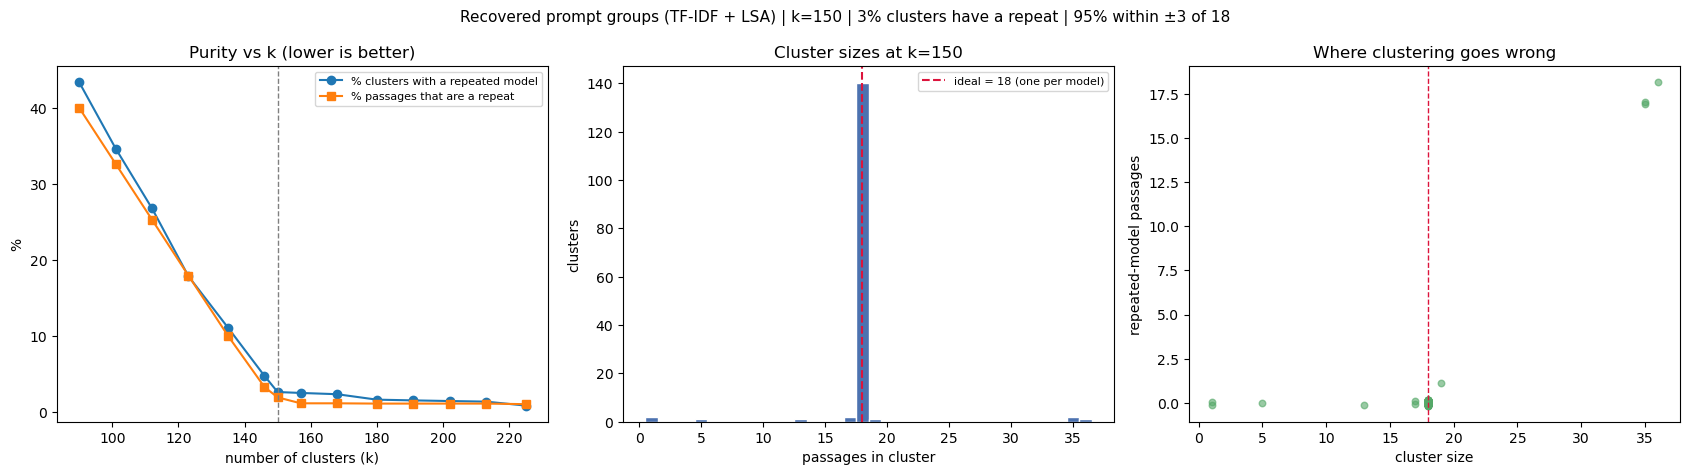

In [21]:
sizes = df.groupby("group").size()
reps = df.groupby("group")["model"].apply(lambda s: s.duplicated().sum())

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].plot(sweep.k, sweep.pct_clusters_with_repeat, "o-", label="% clusters with a repeated model")
ax[0].plot(sweep.k, sweep.pct_passages_duplicated, "s-", label="% passages that are a repeat")
ax[0].axvline(K, color="gray", ls="--", lw=1)
ax[0].set(xlabel="number of clusters (k)", ylabel="%", title="Purity vs k (lower is better)")
ax[0].legend(fontsize=8)

ax[1].hist(sizes, bins=np.arange(0.5, sizes.max() + 1.5, 1), color="#4C72B0", edgecolor="white")
ax[1].axvline(N_MODELS, color="crimson", ls="--", label=f"ideal = {N_MODELS} (one per model)")
ax[1].set(xlabel="passages in cluster", ylabel="clusters", title=f"Cluster sizes at k={K}")
ax[1].legend(fontsize=8)

ax[2].scatter(sizes, reps + np.random.default_rng(0).uniform(-.15, .15, len(reps)), alpha=.6, s=22, color="#55A868")
ax[2].axvline(N_MODELS, color="crimson", ls="--", lw=1)
ax[2].set(xlabel="cluster size", ylabel="repeated-model passages", title="Where clustering goes wrong")

fig.suptitle(f"Recovered prompt groups ({METHOD}) | k={K} | {q['pct_clusters_with_repeat']:.0f}% clusters have a repeat"
             f" | {q['pct_clusters_size_ok']:.0f}% within ±3 of {N_MODELS}", fontsize=11)
fig.tight_layout(); fig.savefig(f"{OUT}/group_recovery.png", dpi=150); plt.show()

**Reading it:** left — repeats should fall to near 0 around the expected k; middle — most clusters should sit at the red line;
right — big clusters with repeats are two prompts merged (try larger k or e5); tiny clusters are prompts split apart.

## 5. Why the groups matter: random CV vs grouped CV
Same model (character n-grams + class-balanced logistic regression), two ways of splitting. Only the grouped score
estimates the leaderboard, because test prompts are unseen.

Expect the **random split to score lower, not higher**. Each model answers each prompt once, so in a random split the
other passages on the same prompt sit in training labelled with *other* models. The classifier learns "this topic means
those models" and is pushed away from the right answer. A random split is therefore misleading in both directions.

In [22]:
clf = make_pipeline(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2, max_features=200_000),
    LogisticRegression(C=5, class_weight="balanced", max_iter=2000),
)
X, y, g = df["text"], df["model"], df["group"]

pred_rand = cross_val_predict(clf, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), n_jobs=-1)
pred_grp  = cross_val_predict(clf, X, y, cv=GroupKFold(5), groups=g, n_jobs=-1)
scores = {"Random 5-fold": balanced_accuracy_score(y, pred_rand),
          "GroupKFold (recovered prompts)": balanced_accuracy_score(y, pred_grp)}
scores

{'Random 5-fold': np.float64(0.11445190156599552),
 'GroupKFold (recovered prompts)': np.float64(0.3130151628138206)}

In [23]:
# ---- Cell A: style features from the paper ----
import re
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.preprocessing import FunctionTransformer, StandardScaler

FUNC_WORDS = ["the", "and", "to", "of", "a", "in", "is", "that", "it", "this", "such", "overall", "here", "based"]
MD = {"bold": r"\*\*[^*\n]+\*\*", "italic": r"(?<![*\w])[*_][^*_\n]+[*_](?![*\w])",
      "header": r"(?m)^#{1,6}\s", "enum": r"(?m)^\s*\d+[.)]\s", "bullet": r"(?m)^\s*[-*•]\s", "code": r"```"}
PUNCT = {"emdash": "—", "semicolon": ";", "colon": ":", "excl": "!", "question": r"\?", "paren": r"\(", "newline": r"\n"}

def style_feats(texts):
    rows = []
    for t in texts:
        words = re.findall(r"[A-Za-z']+", t.lower()); n = max(len(words), 1)
        sents = max(len(re.findall(r"[.!?](\s|$)", t)), 1)
        r = {k: len(re.findall(p, t)) for k, p in {**MD, **PUNCT}.items()}
        r.update({f"fw_{w}": words.count(w) / n for w in FUNC_WORDS})
        r.update(n_words=n, avg_word_len=sum(map(len, words)) / n, words_per_sent=n / sents)
        rows.append(r)
    return pd.DataFrame(rows).values

def first_words(texts, k=3):
    return [" ".join(f"w{i}_{w}" for i, w in enumerate(re.findall(r"[A-Za-z']+", t.lower())[:k])) for t in texts]

# share of passages that contain each markdown/punctuation element
cols = [*MD, *PUNCT, *[f"fw_{w}" for w in FUNC_WORDS], "n_words", "avg_word_len", "words_per_sent"]
pd.DataFrame(style_feats(df["text"]), columns=cols)[[*MD, *PUNCT]].gt(0).mean().round(3).to_frame("share").T

,bold,italic,header,enum,bullet,code,emdash,semicolon,colon,excl,question,paren,newline
share,0.0,0.006,0.0,0.0,0.0,0.0,0.39,0.387,0.521,0.003,0.031,0.011,0.0


In [24]:
# ---- Cell B: combined model vs the char-only baseline (same GroupKFold) ----
features = FeatureUnion([
    ("char",  TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2, max_features=200_000)),
    ("word",  TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2)),   # keep stopwords on purpose
    ("first", make_pipeline(FunctionTransformer(first_words), CountVectorizer(token_pattern=r"\S+", binary=True))),
    ("style", make_pipeline(FunctionTransformer(style_feats), StandardScaler())),
])
clf_idio = make_pipeline(features, LogisticRegression(C=5, class_weight="balanced", max_iter=3000))
pred_idio = cross_val_predict(clf_idio, X, y, cv=GroupKFold(5), groups=df["group"], n_jobs=-1)
scores["+ word, first-words, style"] = balanced_accuracy_score(y, pred_idio)
pd.Series(scores).round(3)

Random 5-fold                     0.114
GroupKFold (recovered prompts)    0.313
+ word, first-words, style        0.283
dtype: float64

In [25]:
# ---- Cell C: each model's characteristic phrases (paper Fig. 6) ----
vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=3)
lr = LogisticRegression(C=5, class_weight="balanced", max_iter=3000).fit(vec.fit_transform(X), y)
vocab = np.array(vec.get_feature_names_out())
pd.Series({m: ", ".join(vocab[np.argsort(lr.coef_[i])[::-1][:8]]) for i, m in enumerate(lr.classes_)},
          name="top phrases").to_frame()

,top phrases
claude-fable-5,"nothing, water, she, years, dissolves, link, r..."
claude-opus-4-6,"that, something, the architecture, most, cathe..."
claude-opus-4-8,"you, quietly, this, single, that, we, here, upon"
claude-opus-5,"is, it, never, so, of it, that, no one, arithm..."
claude-sonnet-5,"itself, this, entirely, this is, isn, self, si..."
gemini-3.1-pro-preview,"of, profound, this, absolute, it is, our, of t..."
gemini-3.6-flash,"of, human, fundamental, silent, dynamic, compl..."
gemini-3.7-flash,"an, profound, fundamentally, within the, acros..."
gemini-3.8-flash,"an, transforming, as an, these, effortlessly, ..."
glm-5.3,"itself, every, so, now, fragments, way, two, b..."


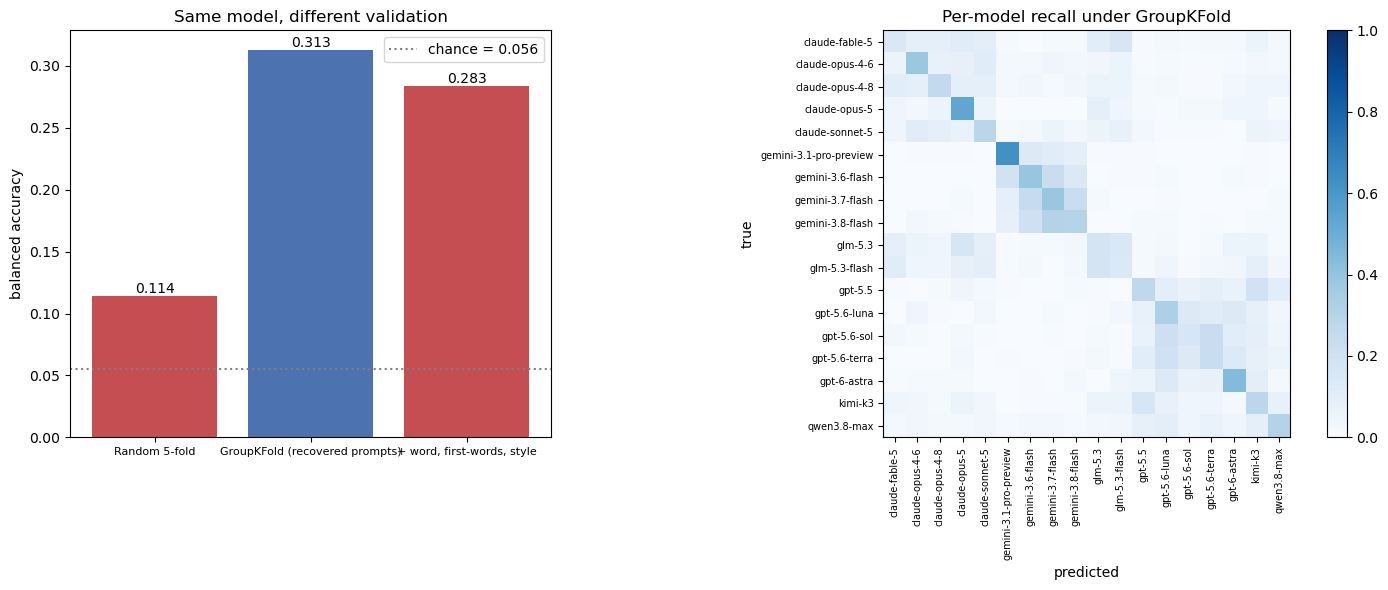

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.5]})
b = ax[0].bar(list(scores), list(scores.values()), color=["#C44E52", "#4C72B0"])
ax[0].bar_label(b, fmt="%.3f"); ax[0].axhline(1 / N_MODELS, color="gray", ls=":", label=f"chance = {1/N_MODELS:.3f}")
ax[0].set(ylabel="balanced accuracy", title="Same model, different validation"); ax[0].legend()
ax[0].tick_params(axis="x", labelsize=8)

order = sorted(y.unique())
cm = confusion_matrix(y, pred_grp, labels=order, normalize="true")
im = ax[1].imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax[1].set_xticks(range(len(order)), order, rotation=90, fontsize=7)
ax[1].set_yticks(range(len(order)), order, fontsize=7)
ax[1].set(xlabel="predicted", ylabel="true", title="Per-model recall under GroupKFold")
fig.colorbar(im, ax=ax[1], fraction=.03)
fig.tight_layout(); fig.savefig(f"{OUT}/grouped_cv_baseline.png", dpi=150); plt.show()

In [28]:
# ---- Prompt-centering + one-model-per-prompt assignment ----
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder().fit(y); Y = le.transform(y); K = len(le.classes_)
G = df["group"].to_numpy()

def featurize(train_text, test_text):
    """char + word TF-IDF, fit on the training fold only, returned dense (float32)."""
    char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2, max_features=20_000, dtype=np.float32)
    word = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2, max_features=15_000, dtype=np.float32)
    A = np.hstack([char.fit_transform(train_text).toarray(), word.fit_transform(train_text).toarray()])
    B = np.hstack([char.transform(test_text).toarray(),  word.transform(test_text).toarray()])
    return A, B

def center(M, groups):
    """Subtract each prompt group's mean: removes the topic, keeps the author's style."""
    out = M.copy()
    for g in np.unique(groups):
        i = groups == g
        out[i] -= M[i].mean(axis=0)
    return out

def assign(P, groups):
    """Each model answers each prompt once -> best one-to-one match inside every group."""
    pred = P.argmax(1)
    for g in np.unique(groups):
        idx = np.where(groups == g)[0]
        cost = np.tile(-np.log(P[idx] + 1e-9), int(np.ceil(len(idx) / K)))  # allow repeats only if group > K
        r, c = linear_sum_assignment(cost)
        pred[idx[r]] = c % K
    return pred

res = {"plain": [], "+ centering": [], "+ centering + assignment": []}
for tr, te in GroupKFold(5).split(X, Y, G):
    A, B = featurize(X.iloc[tr], X.iloc[te])
    for name, (a, b) in {"plain": (A, B), "+ centering": (center(A, G[tr]), center(B, G[te]))}.items():
        lr = LogisticRegression(C=5, class_weight="balanced", max_iter=2000).fit(a, Y[tr])
        P = lr.predict_proba(b)
        res[name].append(balanced_accuracy_score(Y[te], P.argmax(1)))
        if name == "+ centering":
            res["+ centering + assignment"].append(balanced_accuracy_score(Y[te], assign(P, G[te])))
    print({k: round(v[-1], 3) for k, v in res.items()})

pd.DataFrame({k: [np.mean(v), np.std(v)] for k, v in res.items()}, index=["mean", "std"]).T.round(3)

{'plain': np.float64(0.322), '+ centering': np.float64(0.368), '+ centering + assignment': np.float64(0.409)}
{'plain': np.float64(0.306), '+ centering': np.float64(0.365), '+ centering + assignment': np.float64(0.425)}
{'plain': np.float64(0.312), '+ centering': np.float64(0.388), '+ centering + assignment': np.float64(0.427)}
{'plain': np.float64(0.299), '+ centering': np.float64(0.401), '+ centering + assignment': np.float64(0.436)}
{'plain': np.float64(0.308), '+ centering': np.float64(0.384), '+ centering + assignment': np.float64(0.413)}


,mean,std
plain,0.309,0.007
+ centering,0.381,0.013
+ centering + assignment,0.422,0.010


## 6. Save

In [27]:
df.drop(columns=["n_words"]).to_csv(f"{OUT}/train_with_groups.csv", index=False)
sweep.to_csv(f"{OUT}/cluster_sweep.csv", index=False)
print("saved to", OUT)

saved to .


## Next steps
- Prompt-centering: subtract each group's mean feature vector before the classifier.
- Embeddings (e5) + small head; supervised contrastive training with positives = same model, different group.
- Two-stage (organization → model) and Hungarian assignment within each test group.
- Log every run to MLflow with `cv_scheme`, `k`, and `cluster_quality` as params so the drift/monitoring story has a baseline.